## NAIVE COUNT

What is the longest sequence at the beginning that these two strings have in common?

In [1]:
## read two strings and return the longest common prefix
def longestCommonPrefix(s1, s2):
    i = 0
    while i < len(s1) and i < len(s2) and s1[i] == s2[i]:
        i += 1
        
    return s1[:i]
longestCommonPrefix("ACCATGT", "ACCAGAC")

'ACCA'

MATCH STRING

In [2]:
## match two strings and return True if they are equal, False otherwise
def match (s1, s2):
    if len(s1) != len(s2):
        return False
    for i in range(len(s1)):        ## Check each character
        if s1[i] != s2[i]:
            return False
    return True
match("ATGCT", "ATGCT")

True

In [3]:
match("ATCGT", "AACCG")

False

In [4]:
## PYTHON INBUILT FUNCTION
10==20

False

REVERSE COMPLEMENT 

In [5]:
complement = {"A": "T", "T": "A", "C": "G", "G": "C"}
complement["C"]

'G'

In [6]:
def reverseComplement (s):
    complement = {"A": "T", "T": "A", "C": "G", "G": "C"}
    revComp = ""
    for base in s:
        revComp += complement[base]
    return revComp[::-1]

reverseComplement("ACCGTCG")

'CGACGGT'

class Index(object):
    def __init__(self, t, k):
        ''' Create index from all substrings of size 'length' '''
        self.k = k  # k-mer length (k)
        self.index = []
        for i in range(len(t) - k + 1):  # for each k-mer
            self.index.append((t[i:i+k], i))  # add (k-mer, offset) pair
        self.index.sort()  # alphabetize by k-mer
    
    def query(self, p):
        ''' Return index hits for first k-mer of P '''
        kmer = p[:self.k]  # query with first k-mer
        i = bisect.bisect_left(self.index, (kmer, -1))  # binary search
        hits = []
        while i < len(self.index):  # collect matching index entries
            if self.index[i][0] != kmer:
                break
            hits.append(self.index[i][1])
            i += 1
        return hits

def overlap(a, b, min_length=3):
    """ Return length of longest suffix of 'a' matching
        a prefix of 'b' that is at least 'min_length'
        characters long.  If no such overlap exists,
        return 0. """
    start = 0  # start all the way at the left
    while True:
        start = a.find(b[:min_length], start)  # look for b's prefix in a
        if start == -1:  # no more occurrences to right
            return 0
        # found occurrence; check for full suffix/prefix match
        if b.startswith(a[start:]):
            return len(a)-start
        start += 1  # move just past previous match

In [7]:
## download directly from the internet and save to a file
!wget --no-check-certificate https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/lambda_virus.fa

--2026-10-31 13:50:39--  https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/lambda_virus.fa
Resolving d28rh4a8wq0iu5.cloudfront.net (d28rh4a8wq0iu5.cloudfront.net)... 108.156.162.135, 108.156.162.31, 108.156.162.59, ...
Connecting to d28rh4a8wq0iu5.cloudfront.net (d28rh4a8wq0iu5.cloudfront.net)|108.156.162.135|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 49270 (48K) [application/octet-stream]
Saving to: 'lambda_virus.fa.57'

     0K .......... .......... .......... .......... ........  100% 2.03M=0.02s

2026-10-31 13:50:41 (2.03 MB/s) - 'lambda_virus.fa.57' saved [49270/49270]



In [8]:
from Bio import SeqIO
from Bio.Seq import Seq

# Load the FASTA file
records = list(SeqIO.parse(r"C:\Users\Akintayo\Downloads\Bioinfornatics\lambda_virus.fa", "fasta"))

print("Number of sequences:", len(records))

for i, record in enumerate(records, start=0):
    print(f"\nSequence {i}")
    print("ID:", record.id)
    print("Description:", record.description)
    print("Length:", len(record.seq))

Number of sequences: 1

Sequence 0
ID: gi|9626243|ref|NC_001416.1|
Description: gi|9626243|ref|NC_001416.1| Enterobacteria phage lambda, complete genome
Length: 48502


In [9]:
genome = records[0].seq
genome[ :100]

Seq('GGGCGGCGACCTCGCGGGTTTTCGCTATTTATGAAAATTTTCCGGTTTAAGGCG...ACC')

In [10]:

#def readGenome(filename):
 #   genome =''
  #  with open(filename, 'r') as f:
   #     for line in f:
    #        if not line[0] == '>':
     #           genome += line.strip()
    #return genome

#genome = readGenome('lambda_virus.fa.1')
#genome[ :100]

In [11]:
len (genome)

48502

count frequency of each base

In [12]:
counts = {'A': 0, 'C': 0, 'G': 0, 'T': 0}
for base in genome:
    counts[base] += 1
print(counts)

{'A': 12334, 'C': 11362, 'G': 12820, 'T': 11986}


Or use python module


In [13]:
import collections
counts = collections.Counter(genome)
counts


Counter({'G': 12820, 'A': 12334, 'T': 11986, 'C': 11362})

Question 1
How many times does 
AGGT
AGGTstart verbatim, AGGT, end verbatim or its reverse complement (
ACCT
ACCTstart verbatim, ACCT, end verbatim) occur in the lambda virus genome?  E.g. if 
AGGT
AGGTstart verbatim, AGGT, end verbatim occurs 10 times and 
ACCT
ACCTstart verbatim, ACCT, end verbatim occurs 12 times, you should report 22.

## Kmer index approach

In [14]:
class Index(object):
    def __init__(self, t, k):
        ''' Create index from all substrings of size 'length' '''
        self.k = k  # k-mer length (k)
        self.index = []
        for i in range(len(t) - k + 1):  # for each k-mer
            self.index.append((t[i:i+k], i))  # add (k-mer, offset) pair
        self.index.sort()  # alphabetize by k-mer
    
    def query(self, p):
        ''' Return index hits for first k-mer of P '''
        kmer = p[:self.k]  # query with first k-mer
        i = bisect.bisect_left(self.index, (kmer, -1))  # binary search
        hits = []
        while i < len(self.index):  # collect matching index entries
            if self.index[i][0] != kmer:
                break
            hits.append(self.index[i][1])
            i += 1
        return hits

In [15]:
import bisect

# Build a 4-mer index
index = Index(genome, 4)

# Find AGGT
aggt_hits = index.query("AGGT")

# Find reverse complement ACCT
acct_hits = index.query("ACCT")

# Total number of occurrences
answer = len(aggt_hits) + len(acct_hits)

print("AGGT occurrences:", len(aggt_hits))
print("ACCT occurrences:", len(acct_hits))
print("Total:", answer)

AGGT occurrences: 150
ACCT occurrences: 156
Total: 306


## Direct Method

In [16]:
## how many times does a pattern occur in a genome
def naive_count(pattern, genome):
    count = 0
    reverse_complement = reverseComplement(pattern)
    for i in range(len(genome) - len(pattern) + 1):
        if genome[i:i+len(pattern)] == pattern or genome[i:i+len(pattern)] == reverse_complement:
            count += 1
    return count, reverse_complement
naive_count("AGGT", genome)

(306, 'ACCT')

Question 2
How many times does 
TTAA
TTAAstart verbatim, TTAA, end verbatim or its reverse complement occur in the lambda virus genome?  

Hint: 
TTAA
TTAAstart verbatim, TTAA, end verbatim and its reverse complement are equal, so remember not to double count.

## Kmer calculation 

In [17]:

# Find TTAA
aggt_hits = index.query("TTAA")

# Find reverse complement ACCT
##acct_hits = index.query("TTAA")

# Total number of occurrences
##answer = len(aggt_hits) + len(acct_hits)      the reverse compliment of TTAA is TTAA itself, so we can just count the occurrences of TTAA in the genome and its reverse complement (which is also TTAA). Therefore, we can simply use the length of aggt_hits to get the total occurrences of TTAA.

print("TTAA occurrences:", len(aggt_hits))
##print("TTAA occurrences:", len(acct_hits))
print("Total:", answer)

TTAA occurrences: 195
Total: 306


## second approach

In [18]:
naive_count("TTAA", genome)

(195, 'TTAA')

What is the offset of the leftmost occurrence of 
ACTAAGT
ACTAAGTstart verbatim, ACTAAGT, end verbatim or its reverse complement in the Lambda virus genome?  E.g. if the leftmost occurrence of 
ACTAAGT
ACTAAGTstart verbatim, ACTAAGT, end verbatim is at offset 40 (0-based) and the leftmost occurrence of its reverse complement 
ACTTAGT
ACTTAGTstart verbatim, ACTTAGT, end verbatim is at offset 29, then report 29.

## Kmer index

In [19]:
# Build a 7-mer index
index = Index(genome, 7)

# Find AGGT
hits = index.query("ACTAAGT")

print(hits)
min(hits)

[27733, 45382]


27733

In [20]:
## Occurence of index of a pattern in a genome
def naive_find(pattern, genome):
    
    reverse_complement = reverseComplement(pattern)
    for i in range(len(genome) - len(pattern) + 1):
        if genome[i:i+len(pattern)] == pattern or genome[i:i+len(pattern)] == reverse_complement:
            return i
    return -1

naive_find("ACTAAGT", genome)

26028

4.
Question 4
What is the offset of the leftmost occurrence of 
AGTCGA
AGTCGAstart verbatim, AGTCGA, end verbatim or its reverse complement in the Lambda virus genome?

## Kmers


In [21]:
pattern = "AGTCGA"

# Find reverse complement
rc = reverseComplement(pattern)

print("Pattern:", pattern)
print("Reverse complement:", rc)

# Build index
index = Index(genome, len(pattern))

# Search both
hits_pattern = index.query(pattern)
hits_rc = index.query(rc)

print("Pattern hits:", hits_pattern)
print("Reverse-complement hits:", hits_rc)

# Combine hits
all_hits = hits_pattern + hits_rc

# Find leftmost occurrence
answer = min(all_hits)

print("Leftmost offset:", answer)

Pattern: AGTCGA
Reverse complement: TCGACT
Pattern hits: [18005, 23320, 33657, 44806]
Reverse-complement hits: [450, 1908, 2472, 41927, 45369]
Leftmost offset: 450


## Second method

In [22]:
naive_find("AGTCGA", genome)

450

5.
Question 5
As we will discuss, sometimes we would like to find approximate matches for P in T. That is, we want to find occurrences with one or more differences.

For Questions 5 and 6, make a new version of the 
naive
naivestart verbatim, naive, end verbatim function called 
naive_2mm
naive_2mmstart verbatim, naive_2mm, end verbatim that allows up to 2 mismatches per occurrence. Unlike for the previous questions, do not consider the reverse complement here.  We're looking for approximate matches for P itself, not its reverse complement.

￼

For example, 
ACTTTA
ACTTTAstart verbatim, ACTTTA, end verbatim occurs twice in 
ACTTACTTGATAAAGT
ACTTACTTGATAAAGTstart verbatim, ACTTACTTGATAAAGT, end verbatim, once at offset 0 with 2 mismatches, and once at offset 4 with 1 mismatch. So 
naive_2mm('ACTTTA', 'ACTTACTTGATAAAGT')
naive_2mm(’ACTTTA’, ’ACTTACTTGATAAAGT’)start verbatim, naive_2mm('ACTTTA', 'ACTTACTTGATAAAGT'), end verbatim should return the list 
[0, 4]
[0, 4]start verbatim, [0, 4], end verbatim.

Hint: See 
 this notebook
 for a few examples you can use to test your 
naive_2mm
naive_2mmstart verbatim, naive_2mm, end verbatim function.

How many times does 
TTCAAGCC
TTCAAGCCstart verbatim, TTCAAGCC, end verbatim occur in the Lambda virus genome when allowing up to 2 mismatches? 

In [23]:
def naive_2mm(p, g, max_mismatches=2):
    """
    Find all positions where 'pattern' appears in 'genome'
    allowing up to max_mismatches mismatches.
    """
    positions = []
    for i in range(len(g) - len(p) + 1):
        mismatches = 0
        for j in range(len(p)):
            if g[i + j] != p[j]:
                mismatches += 1
                if mismatches > max_mismatches:
                    break
        if mismatches <= max_mismatches:
            positions.append(i)
    return positions

In [24]:
p = 'CTGT'
ten_as = 'AAAAAAAAAA'
t = ten_as + 'CTGT' + ten_as + 'CTTT' + ten_as + 'CGGG' + ten_as
occurrences = naive_2mm(p, t)
print(occurrences)

[10, 24, 38]


In [25]:
p = 'TTCAAGCC'
occurrence = naive_2mm(p, genome)

print(len(occurrence))


191


6.
Question 6
What is the offset of the leftmost occurrence of 
AGGAGGTT
AGGAGGTTstart verbatim, AGGAGGTT, end verbatim in the Lambda virus genome when allowing up to 2 mismatches?

In [26]:

def naive_2mm_offset_position(pattern, genome, max_mismatches=2):
    
    reverse_complement = reverseComplement(pattern)

    for i in range(len(genome) - len(pattern) + 1):
        
        mismatches_pattern = 0
        mismatches_rc = 0
        
        for j in range(len(pattern)):
            
            if genome[i + j] != pattern[j]:
                mismatches_pattern += 1
                
            if genome[i + j] != reverse_complement[j]:
                mismatches_rc += 1
            
            if (mismatches_pattern > max_mismatches and
                mismatches_rc > max_mismatches):
                break
        
        if (mismatches_pattern <= max_mismatches or
            mismatches_rc <= max_mismatches):
            return i
    
    return -1

In [27]:
naive_2mm_offset_position("AGGAGGTT", genome)

49

In [28]:
## Download the file from the internet and save it to a file
!wget.exe --no-check-certificate https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/SRR835775_1.first1000.fastq

--2026-10-31 13:50:49--  https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/SRR835775_1.first1000.fastq
Resolving d28rh4a8wq0iu5.cloudfront.net (d28rh4a8wq0iu5.cloudfront.net)... 108.156.162.135, 108.156.162.31, 108.156.162.59, ...
Connecting to d28rh4a8wq0iu5.cloudfront.net (d28rh4a8wq0iu5.cloudfront.net)|108.156.162.135|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 224786 (220K) [application/octet-stream]
Saving to: 'SRR835775_1.first1000.fastq.48'

     0K .......... .......... .......... .......... .......... 22% 1.03M 0s
    50K .......... .......... .......... .......... .......... 45% 2.53M 0s
   100K .......... .......... .......... .......... .......... 68% 1.13M 0s
   150K .......... .......... .......... .......... .......... 91% 3.81M 0s
   200K .......... .........                                  100% 4.50M=0.1s

2026-10-31 13:50:49 (1.68 MB/s) - 'SRR835775_1.first1000.fastq.48' saved [224786/224786]



In [29]:
def readFastq(filename):
    sequences = []
    qualities = []
    with open(filename) as fh:
        while True:
            fh.readline()  # skip name line first line
            seq = fh.readline().rstrip()  # read base sequence  second line
            fh.readline()  # skip placeholder line  third line
            qual = fh.readline().rstrip()  # base quality line  # fourth line
            if len(seq) == 0:       ## break if the sequence is empty or greater than 0
                break
            sequences.append(seq)
            qualities.append(qual)
    return sequences, qualities
seqs, quals = readFastq('SRR835775_1.first1000.fastq')

In [30]:
print(seqs)
print(quals)

['...']
['???B1ADDD8??BB+C?B+:AA883CEE8?C3@DDD3)?D2;DC?8?=BAD=@C@(.6.6=A?=?@##################################', 'CCCFFFFFGHHGHJJJJJIJGIIJJJJJJJIJIJJJJJFJJFGIIIIH=CBFCF=CCEG)=>EHB2@@DEC>;;?=;(=?BBD?59?BA###########', '@@<DD?DDHHH<CBHII:CFGIGAGHIIG?CCGGE0BDHIIHIGICH8=FHGI=@EHGGGEEHH>);?CC@.;(=;?59,5<A599?CB>ABBCB><88A', '@CCFFDDFHHHDFHIJJCGGIJJHIIHJC?DHHIJ0?DGHI9BBFHICGGIGI=CDEGI=?AAEF7@?################################', '@<@FDFDDBBFHH@EBGGGEH@FFHE;EHIEGGBHG?)9?8BDGGBGGBCDGI=93=C6==C;CCD(?@>@#############################', 'CCCFFDFDHGHHDHHGIIIHGIJ<GBBBFBGGHDIH@B)?)0?F>DB#####################################################', "???=DD0@3ADB<<CE;+3<;EE?1:)1?C1?3BDCB@;)99)0;@;)-(.7A'55A1?.6;(6;.5;;??#############################", "@@@DDF?EFFHA;DDHGI<FDFGECCHF:C9DH9F3):??GHB)BFHEAHBG;C';C@EE45?#####################################", '@@@FADDFHGBFFHJJJFGEHGGGGCEGHCBFGGJ:D?FGIDHDFGIBFDGIJ=CEHDH7?=BFD@A;>AB5=2=?BB######################', '@CCFFADDHHH<CBGIICGGHIJI?FFGHJ?DHGIJ?DGIIIBFCHHI8@@GEE

## Create Histogram

In [31]:
def phred33ToQ(qual):  ## this takes a single character as input and returns the corresponding quality score
    return ord(qual) - 33  # convert the ASCII character to a quality score by subtracting 33 from the ASCII value of the character

In [32]:
phred33ToQ(';')     ## low qaulity scores means a very low confident in our values 

26

In [33]:
def createHist(qualities):
    hist = [0] * 50
    for qual in qualities:
        for phred in qual:
            q = phred33ToQ(phred)
            hist[q] += 1
    return hist
h = createHist(quals)
print(h)

[0, 0, 6178, 0, 0, 54, 108, 574, 345, 83, 193, 124, 79, 165, 49, 236, 184, 327, 514, 238, 531, 254, 313, 798, 992, 888, 1396, 1488, 993, 1752, 3387, 4487, 3248, 5476, 8375, 11814, 4243, 7827, 6579, 8179, 9349, 8180, 0, 0, 0, 0, 0, 0, 0, 0]


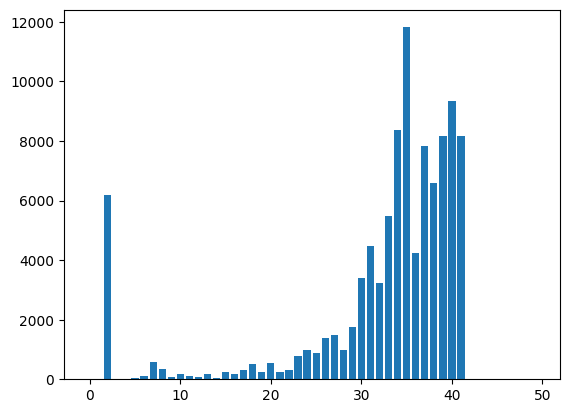

In [34]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.bar(range(len(h)), h)
plt.show()

7.
Question 7
Finally, download and parse the provided FASTQ file containing real DNA sequencing reads derived from a human:

 https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/ERR037900_1.first1000.fastq

Note that the file has many reads in it and you should examine all of them together when answering this question.  The reads are taken from this study:

Ajay, S. S., Parker, S. C., Abaan, H. O., Fajardo, K. V. F., & Margulies, E. H. (2011). Accurate

and comprehensive sequencing of personal genomes. Genome research, 21(9), 1498-1505. 

This dataset has something wrong with it; one of the sequencing cycles is poor quality.

Report which sequencing cycle has the problem.  Remember that a sequencing cycle corresponds to a particular offset in all the reads. For example, if the leftmost read position seems to have a problem consistently across reads, report 0. If the fourth position from the left has the problem, report 3. Do whatever analysis you think is needed to identify the bad cycle. It might help to review the "Analyzing reads by position" video.

In [35]:
def phred33ToQ(qual):   ## this takes a string of quality characters as input and returns a list of corresponding quality scores
    return [ord(c) - 33 for c in qual] ## convert the ASCII characters to quality scores by subtracting 33 from the ASCII values of the characters

In [36]:
def count_poor_reads(quals, threshold=20):
    poor_reads = 0

    for qual in quals:
        scores = phred33ToQ(qual)
        avg_quality = sum(scores) / len(scores)

        if avg_quality < threshold:
            poor_reads += 1
            
    percentage = (poor_reads / len(quals)) * 100
    

    return poor_reads, percentage

poor, percentage = count_poor_reads(quals, threshold=20)

print("Number of poor-quality reads:", poor)
print("Percentage of poor-quality reads:", percentage)

Number of poor-quality reads: 60
Percentage of poor-quality reads: 6.0


## Naive Exact Matching 
def naive (p, t):
    occurrence = []
    for i in range (len(t) - len(p) + 1):   # loop over alignment 
        match = True
        for j in range(len(p)):             # loop over character
           if t[i+j] != p[j]:               # compare character
               match = False                # mismatch; reject alignment 
               break
        if match:
           occurrence.append(i)             # all chars matched; record
    return occurrence 

In [37]:
## Download the file from the internet and save it to a file
!wget --no-check-certificate https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/ERR266411_1.first1000.fastq

--2026-10-31 13:50:54--  https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/ERR266411_1.first1000.fastq
Resolving d28rh4a8wq0iu5.cloudfront.net (d28rh4a8wq0iu5.cloudfront.net)... 108.156.162.135, 108.156.162.31, 108.156.162.59, ...
Connecting to d28rh4a8wq0iu5.cloudfront.net (d28rh4a8wq0iu5.cloudfront.net)|108.156.162.135|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 254384 (248K) [audio/mpeg]
Saving to: 'ERR266411_1.first1000.fastq.37'

     0K .......... .......... .......... .......... .......... 20%  892K 0s
    50K .......... .......... .......... .......... .......... 40% 2.24M 0s
   100K .......... .......... .......... .......... .......... 60% 1.53M 0s
   150K .......... .......... .......... .......... .......... 80% 3.06M 0s
   200K .......... .......... .......... .......... ........  100% 2.25M=0.1s

2026-10-31 13:50:55 (1.65 MB/s) - 'ERR266411_1.first1000.fastq.37' saved [254384/254384]



In [38]:
def readFastq(filename):
    sequences = []
    qualities = []
    with open(filename) as fh:
        while True:
            fh.readline()  # skip name line first line
            seq = fh.readline().rstrip()  # read base sequence  second line
            fh.readline()  # skip placeholder line  third line
            qual = fh.readline().rstrip()  # base quality line  # fourth line
            if len(seq) == 0:       ## break if the sequence is empty or greater than 0
                break
            sequences.append(seq)
            qualities.append(qual)
    return sequences, qualities

In [39]:
## Genome Alignment

lambda_reads, _ = readFastq('ERR266411_1.first1000.fastq')

def reverse_complement(seq):
    complement = str.maketrans("ACGTN", "TGCAN")
    return seq.translate(complement)[::-1]

In [40]:
## Naive Exact Matching 
def naive (p, t):
    occurrence = []
    for i in range (len(t) - len(p) + 1):   # loop over alignment 
        match = True
        for j in range(len(p)):             # loop over character
           if t[i+j] != p[j]:               # compare character
               match = False                # mismatch; reject alignment 
               break
        if match:
           occurrence.append(i)             # all chars matched; record
    return occurrence 

In [41]:
numMatched = 0
n = 0

for r in lambda_reads:
    forward_matches = naive(r, genome)
    
    reverse_matches = naive(reverse_complement(r), genome)

    n += 1

    if len(forward_matches) > 0 or len(reverse_matches) > 0:
        numMatched += 1

print('%d / %d reads matched the genome!' % (numMatched, n))

0 / 1000 reads matched the genome!


In [42]:
r = lambda_reads[0]

print("READ:")
print(r)

print("\nREVERSE COMPLEMENT:")
print(reverse_complement(r))

print("\nFORWARD MATCH:")
print(naive(r, genome))

print("\nREVERSE-COMPLEMENT MATCH:")
print(naive(reverse_complement(r), genome))

READ:
TAAACAAGCAGTAGTAATTCCTGCTTTATCAAGATAATTTTTCGACTCATCAGAAATATCCGAAAGTGTTAACTTCTGCGTCATGGAAGCGATAAAACTC

REVERSE COMPLEMENT:
GAGTTTTATCGCTTCCATGACGCAGAAGTTAACACTTTCGGATATTTCTGATGAGTCGAAAAATTATCTTGATAAAGCAGGAATTACTACTGCTTGTTTA

FORWARD MATCH:
[]



REVERSE-COMPLEMENT MATCH:
[]


In [43]:
print("Genome length:", len(genome))
print("Genome first 100 bases:")
print(genome[:100])

Genome length: 48502
Genome first 100 bases:
GGGCGGCGACCTCGCGGGTTTTCGCTATTTATGAAAATTTTCCGGTTTAAGGCGTTTCCGTTCTTCTTCGTCATAACTTAATGTTTTTATTTAAAATACC


In [44]:
print("Expected beginning:")
print("GAGTTTTATCGCTTCCATGACGCAGAAGTTA")

print("\nYour genome beginning:")
print(genome[:36])

Expected beginning:
GAGTTTTATCGCTTCCATGACGCAGAAGTTA

Your genome beginning:
GGGCGGCGACCTCGCGGGTTTTCGCTATTTATGAAA


Generate read

In [45]:
import random 
def generateReads(genome, numReads, readLen):               ## generate a list of reads from a genome
    reads = []
    for _ in range(numReads):
        start = random.randint(0, len(genome) - readLen)
        reads.append(genome[start:start + readLen])
    return reads

genome = "ACTG" * 1000  # just a mock genome
reads = generateReads(genome, 100, 100)
print(reads[:5])                                            # show first 5 reads

['TGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGAC', 'GACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACT', 'GACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACT', 'ACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTG', 'TGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGACTGAC']


CALCULATE EDIT DISTANCE 

In [46]:
!wget --no-check-certificate https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/chr1.GRCh38.excerpt.fasta 

--2026-10-31 13:53:34--  https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/chr1.GRCh38.excerpt.fasta
Resolving d28rh4a8wq0iu5.cloudfront.net (d28rh4a8wq0iu5.cloudfront.net)... 108.156.162.59, 108.156.162.125, 108.156.162.31, ...
Connecting to d28rh4a8wq0iu5.cloudfront.net (d28rh4a8wq0iu5.cloudfront.net)|108.156.162.59|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 810105 (791K) [application/octet-stream]
Saving to: 'chr1.GRCh38.excerpt.fasta.16'

     0K .......... .......... .......... .......... ..........  6%  968K 1s
    50K .......... .......... .......... .......... .......... 12% 1.66M 1s
   100K .......... .......... .......... .......... .......... 18% 1.28M 1s
   150K .......... .......... .......... .......... .......... 25% 3.24M 0s
   200K .......... .......... .......... .......... .......... 31% 2.04M 0s
   250K .......... .......... .......... .......... .......... 37% 3.51M 0s
   300K .......... .......... .......... .......... .......... 44% 5

filename = "chr1.GRCh38.excerpt.fasta"

sequence = ""

with open(filename, "r") as f:
    for line in f:
        if not line.startswith(">"):
            sequence += line.strip()

In [47]:
def readFasta(filename):

    sequence = ""

    with open(filename) as fh:
        for line in fh:
            if not line.startswith(">"):
                sequence += line.strip()

    return sequence

In [48]:
sequences= readFasta("chr1.GRCh38.excerpt.fasta.1")

In [49]:
sequence = readFasta("chr1.GRCh38.excerpt.fasta.1")

print("Length:", len(sequence))
print("First 100 bases:", sequence[:100])

Length: 800000
First 100 bases: TTGAATGCTGAAATCAGCAGGTAATATATGATAATAGAGAAAGCTATCCCGAAGGTGCATAGGTCAACAATACTTGAGCCTAACTCAGTAGATCCTAAAA


In [50]:
def editDistance(x, y):
    # Create distance matrix
    D = []
    for i in range(len(x)+1):
        D.append([0]*(len(y)+1))
    # Initialize first row and column of matrix
    for i in range(len(x)+1):
        D[i][0] = i
    for i in range(len(y)+1):
        D[0][i] = i
    # Fill in the rest of the matrix
    for i in range(1, len(x)+1):
        for j in range(1, len(y)+1):
            distHor = D[i][j-1] + 1
            distVer = D[i-1][j] + 1
            if x[i-1] == y[j-1]:
                distDiag = D[i-1][j-1]
            else:
                distDiag = D[i-1][j-1] + 1
            D[i][j] = min(distHor, distVer, distDiag)
    # Edit distance is the value in the bottom right corner of the matrix
    return D[-1][-1]


In [51]:
def best_match(pattern, sequence):

    best_distance = float("inf")
    best_position = None
    best_match = None

    for i in range(len(sequence) - len(pattern) + 1):

        window = sequence[i:i + len(pattern)]

        distance = editDistance(pattern, window)

        if distance < best_distance:
            best_distance = distance
            best_position = i
            best_match = window

    return best_distance, best_position, best_match

2.
Question 2
What is the edit distance of the best match between pattern 
GATTTACCAGATTGAG
GATTTACCAGATTGAGstart verbatim, GATTTACCAGATTGAG, end verbatim and the excerpt of human chromosome 1?  (Don't consider reverse complements.)

In [52]:
sequence = readFasta("chr1.GRCh38.excerpt.fasta.1")

pattern1 = "GCTGATCGATCGTACG"
pattern2 = "GATTTACCAGATTGAG"

print(best_match(pattern1, sequence))
print(best_match(pattern2, sequence))

(3, 380536, 'GCTGATGGATAGTAAG')
(2, 421071, 'GATTTACCAAGATTGA')


Say we are concerned only with overlaps that (a) are exact matches (no differences allowed), and (b) are at least 
k
kstart verbatim, k, end verbatim bases long. To make an overlap graph, we could call 
overlap(a, b, min_length=k)
overlap(a, b, min_length=k)start verbatim, overlap(a, b, min_length=k), end verbatim on every possible pair of reads from the dataset.  Unfortunately, that will be very slow!

Consider this: Say we are using k=6, and we have a read 
a
astart verbatim, a, end verbatim whose length-6 suffix is 
GTCCTA
GTCCTAstart verbatim, GTCCTA, end verbatim.  Say 
GTCCTA
GTCCTAstart verbatim, GTCCTA, end verbatim does not occur in any other read in the dataset.  In other words, the 6-mer 
GTCCTA
GTCCTAstart verbatim, GTCCTA, end verbatim occurs at the end of read 
a
astart verbatim, a, end verbatim and nowhere else.  It follows that 
a
astart verbatim, a, end verbatim's suffix cannot possibly overlap the prefix of any other read by 6 or more characters.

Put another way, if we want to find the overlaps involving a suffix of read 
a
astart verbatim, a, end verbatim and a prefix of some other read, we can ignore any reads that don't contain the length-k suffix of 
a
astart verbatim, a, end verbatim.  This is good news because it can save us a lot of work!

Here is a suggestion for how to implement this idea.  You don't have to do it this way, but this might help you.  Let every k-mer in the dataset have an associated 
Python 
set
setstart verbatim, set, end verbatim
 object
, which starts out empty.  We use a 
Python dictionary
 to associate each k-mer with its corresponding 
set
setstart verbatim, set, end verbatim. (1) For every k-mer in a read, we add the read to the 
set
setstart verbatim, set, end verbatim object corresponding to that k-mer.  If our read is 
GATTA
GATTAstart verbatim, GATTA, end verbatim and k=3, we would add 
GATTA
GATTAstart verbatim, GATTA, end verbatim to the 
set
setstart verbatim, set, end verbatim objects for 
GAT
GATstart verbatim, GAT, end verbatim, 
ATT
ATTstart verbatim, ATT, end verbatim and 
TTA
TTAstart verbatim, TTA, end verbatim.  We do this for every read so that, at the end, each 
set
setstart verbatim, set, end verbatim contains all reads containing the corresponding k-mer.  (2) Now, for each read 
a
astart verbatim, a, end verbatim, we find all overlaps involving a suffix of 
a
astart verbatim, a, end verbatim.  To do this, we take 
a
astart verbatim, a, end verbatim's length-k suffix, find all reads containing that k-mer (obtained from the corresponding 
set
setstart verbatim, set, end verbatim) and call 
overlap(a, b, min_length=k)
overlap(a, b, min_length=k)start verbatim, overlap(a, b, min_length=k), end verbatim for each.

The most important point is that we do not call 
overlap(a, b, min_length=k)
overlap(a, b, min_length=k)start verbatim, overlap(a, b, min_length=k), end verbatim if 
b
bstart verbatim, b, end verbatim does not contain the length-k suffix of 
a
astart verbatim, a, end verbatim.

Download and parse the read sequences from the provided Phi-X FASTQ file. We'll just use their base sequences, so you can ignore read names and base qualities.  Also, no two reads in the FASTQ have the same sequence of bases.  This makes things simpler.

https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/ERR266411_1.for_asm.fastq

Next, find all pairs of reads with an exact suffix/prefix match of length at least 30. Don't overlap a read with itself; if a read has a suffix/prefix match to itself, ignore that match.  Ignore reverse complements.

Hint 1: Your function should not take much more than 15 seconds to run on this 10,000-read dataset, and maybe much less than that.  (Our solution takes about 3 seconds.) If your function is much slower, there is a problem somewhere.

Hint 2: Remember not to overlap a read with itself. If you do, your answers will be too high.

Hint 3: You can test your implementation by making up small examples, then checking that (a) your implementation runs quickly, and (b) you get the same answer as if you had simply called 
overlap(a, b, min_length=k)
overlap(a, b, min_length=k)start verbatim, overlap(a, b, min_length=k), end verbatim on every pair of reads.  We also have provided 
a couple examples you can check against
.

Picture the overlap graph corresponding to the overlaps just calculated.  How many edges are in the graph?  In other words, how many distinct pairs of reads overlap?

def overlap(a, b, min_length=3):
    """ Return length of longest suffix of 'a' matching
        a prefix of 'b' that is at least 'min_length'
        characters long.  If no such overlap exists,
        return 0. """
    start = 0  # start all the way at the left
    while True:
        start = a.find(b[:min_length], start)  # look for b's prefix in a
        if start == -1:  # no more occurrences to right
            return 0
        # found occurrence; check for full suffix/prefix match
        if b.startswith(a[start:]):
            return len(a)-start
        start += 1  # move just past previous match

def find_overlaps(reads, k):

    index = {}

    # Build k-mer index
    for read in reads:

        for i in range(len(read) - k + 1):

            kmer = read[i:i+k]

            if kmer not in index:
                index[kmer] = set()

            index[kmer].add(read)

    # Find overlaps
    overlaps = []

    for a in reads:

        suffix = a[-k:]

        candidates = index.get(suffix, set())

        for b in candidates:

            if a == b:
                continue

            overlap_length = overlap(a, b, min_length=k)

            if overlap_length > 0:
                overlaps.append((a, b, overlap_length))

    return overlaps

In [53]:
def readFastq(filename):
    sequences = []
    qualities = []
    with open(filename) as fh:
        while True:
            fh.readline()  # header line (@)
            seq = fh.readline().strip()  # sequence
            fh.readline()  # plus line (+)
            qual = fh.readline().strip()  # quality
            if not seq:
                break
            sequences.append(seq)
            qualities.append(qual)
    return sequences, qualities
reads, qualities = readFastq('ERR266411_1.for_asm.fastq')
print("Number of reads:", len(reads))
print(qualities[:5])  # print first 5 quality strings
print(reads[:5])  # print first 5 sequences


Number of reads: 10000
['B@DFEFFFGEGGGHEHGHGHGGGGHIFGFIFHICFGHGHGJGHFGHGIHEHGGHJGFEFHGHEGGHHGHIFGFGDIFGGFGGGFHGGGHGGGAGIFGGCG', "=@@CEBF@BGBG6GF1E<04C3E7E.9G=H<H:HH;HBH;G69F7,7DG((EG8A8,-5-8,?,,,AE>C,B?,,,64$AC'+'='+4'3*4+E322*'(", 'A@DFEFFFGDGGGHFHHHGHGGFGHILGFGEHHHFHHFIGHGHFGHGGGEHGGHJGGHFGFGHHEHFGHICKFGJEIGGIFGGGHGGFHIEEGGEFGKGD', 'B@DFEHFEGEGGGHGFGHGHFFGGGI@GDFHHFFHGHGGFHCHFGHCIGEH9CHGEFGFHFDHEIHCGFGFDDCCGIDGIGKGGHGCFGIFGG;HFGFIE', 'B@DFEDFEGGGGGFFHEHGIGGGGFIGGHHFHHHHGHGFGHHHFGEGFGGHGGHJGGHFHGEHH,HGGHFHGFAGEHHGIGCGGFGEFHFFGGDGFEGGD']
['TAAACAAGCAGTAGTAATTCCTGCTTTATCAAGATAATTTTTCGACTCATCAGAAATATCCGAAAGTGTTAACTTCTGCGTCATGGAAGCGATAAAACTC', 'AACAAGCAGTAGTAATTCCTGCTTTATCAAGATAATTTTTCGACTCATCAGAAATATACGAAAGTGTTAACTTCTGCGTCATGGACACGAAAAAACTCCC', 'AACAAGCAGTAGTAATTCCTGCTTTATCAAGATAATTTTTCGACTCATCAGAAATATCCGAAAGTGTTAACTTCTGCGTCATGGAAGCGATAAAACTCTG', 'AGCCGACGTTTTGGCGGCGCAACCTGTGACGACAAATCTGCTCAAATTTATGCGCGCTTCGATAAAAATGATTGGCGTATCCAACCTGCAGAGTTTTATC', 'GACAAATCTGCTCAAATTTATGCGCGCTTCGATAAAAA

In [54]:
def overlap(a, b, min_length=3):
    """ Return length of longest suffix of 'a' matching
        a prefix of 'b' that is at least 'min_length'
        characters long.  If no such overlap exists,
        return 0. """
    start = 0  # start all the way at the left
    while True:
        start = a.find(b[:min_length], start)  # look for b's prefix in a
        if start == -1:  # no more occurrences to right
            return 0
        # found occurrence; check for full suffix/prefix match
        if b.startswith(a[start:]):
            return len(a)-start
        start += 1  # move just past previous match

In [55]:
def find_overlaps(reads, k):

    index = {}

    # Build k-mer index
    for read in reads:

        for i in range(len(read) - k + 1):

            kmer = read[i:i+k]

            if kmer not in index:
                index[kmer] = set()

            index[kmer].add(read)

    # Find overlaps
    overlaps = []

    for a in reads:

        suffix = a[-k:]

        candidates = index.get(suffix, set())

        for b in candidates:

            if a == b:
                continue

            overlap_length = overlap(a, b, min_length=k)

            if overlap_length > 0:
                overlaps.append((a, b, overlap_length))

    return overlaps

In [56]:
pairs = find_overlaps(reads, 30)

print(len(pairs))
print(len(set(pair[0] for pair in pairs)))

904746
7161


| Code/concept     | What it actually does                 | Main use                      |
| ---------------- | ------------------------------------- | ----------------------------- |
| `editDistance()` | Pairwise sequence difference          | Alignment/comparison          |
| `overlap()`      | Exact suffix-prefix overlap           | Read-overlap detection        |
| k-mer index      | Fast candidate lookup                 | Searching/filtering           |
| Overlap graph    | Represents read-to-read relationships | OLC-style assembly concepts   |
| `scs()`          | Brute-force shortest superstring      | Educational assembly model    |
| De Bruijn graph  | Graph based on k-mers                 | Short-read assembly           |
| OLC              | Overlap → layout → consensus          | Especially long-read assembly |


def overlap(a, b, min_length=3):
    """ Return length of longest suffix of 'a' matching
        a prefix of 'b' that is at least 'min_length'
        characters long.  If no such overlap exists,
        return 0. """
    start = 0  # start all the way at the left
    while True:
        start = a.find(b[:min_length], start)  # look for b's suffx in a
        if start == -1:  # no more occurrences to right
            return 0
        # found occurrence; check for full suffix/prefix match
        if b.startswith(a[start:]):
            return len(a)-start
        start += 1  # move just past previous match

import itertools

def scs(ss):
    """ Returns shortest common superstring of given
        strings, which must be the same length """
    shortest_sup = None
    for ssperm in itertools.permutations(ss):
        sup = ssperm[0]  # superstring starts as first string
        for i in range(len(ss)-1):
            # overlap adjacent strings A and B in the permutation
            olen = overlap(ssperm[i], ssperm[i+1], min_length=1)
            # add non-overlapping portion of B to superstring
            sup += ssperm[i+1][olen:]
        if shortest_sup is None or len(sup) < len(shortest_sup):
            shortest_sup = sup  # found shorter superstring
    return shortest_sup  # return shortest

In [57]:
def overlap(a, b, min_length=3):
    """ Return length of longest suffix of 'a' matching
        a prefix of 'b' that is at least 'min_length'
        characters long.  If no such overlap exists,
        return 0. """
    start = 0  # start all the way at the left
    while True:
        start = a.find(b[:min_length], start)  # look for b's suffx in a
        if start == -1:  # no more occurrences to right
            return 0
        # found occurrence; check for full suffix/prefix match
        if b.startswith(a[start:]):
            return len(a)-start
        start += 1  # move just past previous match

import itertools    

def scs(ss):
    """ Returns shortest common superstring of given
        strings, which must be the same length """
    shortest_sup = None
    for ssperm in itertools.permutations(ss):
        sup = ssperm[0]  # superstring starts as first string
        for i in range(len(ss)-1):
            # overlap adjacent strings A and B in the permutation
            olen = overlap(ssperm[i], ssperm[i+1], min_length=1)
            # add non-overlapping portion of B to superstring
            sup += ssperm[i+1][olen:]
        if shortest_sup is None or len(sup) < len(shortest_sup):
            shortest_sup = sup  # found shorter superstring
    return shortest_sup  # return shortest

In [58]:
scs(['CCT', 'TGC', 'TGG', 'GAT', 'ATT'])

'CCTGGATTGC'

ASSEMBLE READS

In [59]:
!wget --no-check-certificate https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/ads1_week4_reads.fq

--2026-10-31 13:56:43--  https://d28rh4a8wq0iu5.cloudfront.net/ads1/data/ads1_week4_reads.fq
Resolving d28rh4a8wq0iu5.cloudfront.net (d28rh4a8wq0iu5.cloudfront.net)... 108.156.162.135, 108.156.162.31, 108.156.162.125, ...
Connecting to d28rh4a8wq0iu5.cloudfront.net (d28rh4a8wq0iu5.cloudfront.net)|108.156.162.135|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 395781 (387K) [video/m2ts]
Saving to: 'ads1_week4_reads.fq.6'

     0K .......... .......... .......... .......... .......... 12% 1.19M 0s
    50K .......... .......... .......... .......... .......... 25% 1.44M 0s
   100K .......... .......... .......... .......... .......... 38% 1.73M 0s
   150K .......... .......... .......... .......... .......... 51% 3.34M 0s
   200K .......... .......... .......... .......... .......... 64% 2.31M 0s
   250K .......... .......... .......... .......... .......... 77% 2.87M 0s
   300K .......... .......... .......... .......... .......... 90% 3.07M 0s
   350K .........

sequence = ""
head = ""

with open(file) as f:
    for line in f:
        line = line.strip()

        if line.startswith(">"):
            header = line
        else:
            sequence += line

print(header)
print(sequence)
    

In [60]:
# Load the FASTAQ file
records = list(SeqIO.parse(r"C:\Users\Akintayo\Downloads\Bioinfornatics\ads1_week4_reads.fq", "fastq"))

print("Number of sequences:", len(records))

for i, record in enumerate(records, start=0):
    print(f"\nSequence {i}")
    print("ID:", record.id)
    print("Description:", record.description)
    print("Length:", len(record.seq))

Number of sequences: 1881

Sequence 0
ID: r0
Description: r0
Length: 100

Sequence 1
ID: r1
Description: r1
Length: 100

Sequence 2
ID: r2
Description: r2
Length: 100

Sequence 3
ID: r3
Description: r3
Length: 100

Sequence 4
ID: r4
Description: r4
Length: 100

Sequence 5
ID: r5
Description: r5
Length: 100

Sequence 6
ID: r6
Description: r6
Length: 100

Sequence 7
ID: r7
Description: r7
Length: 100

Sequence 8
ID: r8
Description: r8
Length: 100

Sequence 9
ID: r9
Description: r9
Length: 100

Sequence 10
ID: r10
Description: r10
Length: 100

Sequence 11
ID: r11
Description: r11
Length: 100

Sequence 12
ID: r12
Description: r12
Length: 100

Sequence 13
ID: r13
Description: r13
Length: 100

Sequence 14
ID: r14
Description: r14
Length: 100

Sequence 15
ID: r15
Description: r15
Length: 100

Sequence 16
ID: r16
Description: r16
Length: 100

Sequence 17
ID: r17
Description: r17
Length: 100

Sequence 18
ID: r18
Description: r18
Length: 100

Sequence 19
ID: r19
Description: r19
Length: 100

Seq

In [61]:
reads = [str(record.seq) for record in SeqIO.parse(r"C:\Users\Akintayo\Downloads\Bioinfornatics\ads1_week4_reads.fq", "fastq")]
print(reads)
print("Number of reads:", len(reads))
print("Read length:", len(reads[0]))

['...']
Number of reads: 1881
Read length: 100


# 2. Exact suffix-prefix overlap

In [62]:
def overlap(a, b, min_length=3):
    """Return length of longest suffix of a matching prefix of b."""
    start = 0

    while True:
        start = a.find(b[:min_length], start)

        if start == -1:
            return 0

        if b.startswith(a[start:]):
            return len(a) - start

        start += 1

# 3. Build k-mer index
#    k-mer -> read IDs containing that k-mer

In [63]:
def build_kmer_index(reads, k):
    index = defaultdict(set)

    for read_id, read in enumerate(reads):

        for i in range(len(read) - k + 1):

            kmer = read[i:i+k]

            index[kmer].add(read_id)

    return index

# 4. Find candidate overlaps

In [64]:
def find_overlap_edges(reads, k):
    index = build_kmer_index(reads, k)

    edges = []

    for a_id, a in enumerate(reads):

        suffix = a[-k:]

        candidates = index.get(suffix, set())

        for b_id in candidates:

            # Never overlap a read with itself
            if a_id == b_id:
                continue

            olen = overlap(reads[a_id], reads[b_id], k)

            if olen >= k:
                edges.append((olen, a_id, b_id))

    return edges


# 5. Greedily select the strongest edges
#    Each read gets at most:
#       one outgoing edge
#       one incoming edge
#    We also avoid cycles.

In [65]:
def choose_edges(reads, edges):

    edges.sort(reverse=True)

    successor = {}
    predecessor = {}

    parent = list(range(len(reads)))
    rank = [0] * len(reads)

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        root_a = find(a)
        root_b = find(b)

        if root_a == root_b:
            return False

        if rank[root_a] < rank[root_b]:
            root_a, root_b = root_b, root_a

        parent[root_b] = root_a

        if rank[root_a] == rank[root_b]:
            rank[root_a] += 1

        return True

    chosen = []

    for olen, a_id, b_id in edges:

        # a already has a successor
        if a_id in successor:
            continue

        # b already has a predecessor
        if b_id in predecessor:
            continue

        # Don't create a cycle
        if find(a_id) == find(b_id):
            continue

        successor[a_id] = b_id
        predecessor[b_id] = a_id

        union(a_id, b_id)

        chosen.append((olen, a_id, b_id))

    return successor, predecessor, chosen


# 6. Build contigs by following the selected links

In [66]:
def build_contigs(reads, successor, predecessor):

    starts = [
        i for i in range(len(reads))
        if i not in predecessor
    ]

    contigs = []

    for start in starts:

        sequence = reads[start]
        order = [start]
        current = start

        while current in successor:

            next_read = successor[current]

            olen = overlap(
                reads[current],
                reads[next_read],
                min_length=1
            )

            # Add only the non-overlapping part
            sequence += reads[next_read][olen:]

            order.append(next_read)
            current = next_read

        contigs.append((sequence, order))

    return contigs

# 7. Run the assembly

In [67]:
from collections import defaultdict

K = 30

edges = find_overlap_edges(reads, K)

successor, predecessor, chosen = choose_edges(reads, edges)

contigs = build_contigs(
    reads,
    successor,
    predecessor
)

contigs.sort(key=lambda x: len(x[0]), reverse=True)

In [68]:
print("Candidate overlap edges:", len(edges))
print("Selected edges:", len(chosen))
print("Number of contigs:", len(contigs))

for i, (contig, order) in enumerate(contigs, start=1):

    print(
        f"Contig {i}: "
        f"length={len(contig)}, "
        f"reads={len(order)}"
    )

Candidate overlap edges: 15661
Selected edges: 1880
Number of contigs: 1
Contig 1: length=15894, reads=1881


In [69]:
output_file = "assembled_contigs.fasta"

with open(output_file, "w") as f:

    for i, (contig, order) in enumerate(contigs, start=1):

        f.write(
            f">contig_{i} "
            f"length={len(contig)} "
            f"reads={len(order)}\n"
        )

        for j in range(0, len(contig), 80):
            f.write(contig[j:j+80] + "\n")

print("Saved:", output_file)


Saved: assembled_contigs.fasta
